# Full one-loop line-of-sight selection in FolpsD — tutorial

This notebook explains and demonstrates the EdS one-loop model of a galaxy sample whose
selection depends on the line of sight (LOS), as implemented on the branch
`feature/selection-1loop-eds`. It is written for researchers who have not seen the
derivation. All physics lives in the package (`folps.selection_*`); the notebook only calls
the public API, plots its output and runs validation checks.

Companion documents: [`docs/selection_1loop_equations.md`](../docs/selection_1loop_equations.md)
(conventions and equations), [`docs/selection_1loop_validation.md`](../docs/selection_1loop_validation.md)
(numerical validation) and [`docs/selection_1loop_sources.md`](../docs/selection_1loop_sources.md)
(sources and recorded corrections).

**Installation (run in a terminal, not in this notebook):**

```bash
git clone https://github.com/cosmodesi/FolpsD && cd FolpsD
git checkout feature/selection-1loop-eds
python -m pip install -e .                     # numpy, scipy, jax, interpax
python -m pip install matplotlib nbconvert ipykernel sympy pytest   # tutorial + tests
# headless execution from the repository root:
python -m jupyter nbconvert --to notebook --execute notebooks/selection_1loop_tutorial.ipynb \
    --output selection_1loop_tutorial.ipynb --ExecutePreprocessor.timeout=1800
```

The main route uses the NumPy backend. FolpsD fixes its backend **at import time**, so the
JAX comparison (section 20) runs in a separate Python process.

## 1. What the model computes

* the redshift-space galaxy **auto** power spectrum \(P(k,\mu)\) and its multipoles at
  **one loop** in standard perturbation theory, renormalized, with **EdS** kernels and a
  **scale-independent** growth rate \(f\);
* the FolpsD **`model="EFT"`** branch: *no* phenomenological Fingers-of-God (FoG) factor.
  Small-scale velocity effects are described by the EFT counterterms
  \(\alpha_{0,2,4}k^2\mu^{2n}P_L\) and stochastic terms instead;
* **BAO IR resummation** is kept. Its exponential \(e^{-k^2\Sigma_s^2(\mu)}\) resums the
  large-scale displacements that smear the BAO wiggles; it is **not** a FoG factor;
* the galaxy sample is **selected** in a way that depends on the LOS \(\hat{\mathbf n}\) (e.g. by
  orientation-dependent fluxes). In the bias expansion this introduces nine new operators
  (one linear, four quadratic, four cubic) built from the LOS velocity gradient
  \(\eta=\partial_\parallel u_\parallel\) and the projected tidal hierarchy \(\Pi^{[n]}_\parallel\). Their
  coefficients enter both the 22 and the 13 one-loop terms and interfere with ordinary
  bias and RSD.

Not covered: cross spectra with selection, massive-neutrino (`fk`) kernels with selection,
FoG-damped models with selection. These raise informative errors.

## 2. Setup and provenance

The backend is chosen **before** importing FolpsD. Paths are relative to the repository,
discovered from the notebook location (override with the environment variable
`FOLPS_REPO_ROOT`). Generated files go to `OUTPUT_DIR` (default
`notebooks/selection_tutorial_outputs`; override with `FOLPS_TUTORIAL_OUTPUT`). Set
`RUN_SLOW_VALIDATION = True` to recompute the independent direct-quadrature checks
(minutes); the quick mode uses the shipped reference fixture and marks recomputations as
*skipped*.

In [1]:
import os, sys, json, time, subprocess, platform, importlib.util
from pathlib import Path

os.environ["FOLPS_BACKEND"] = "numpy"          # must be set before importing folps
RUN_SLOW_VALIDATION = os.environ.get("FOLPS_RUN_SLOW", "0") == "1"
RUN_JAX_PARITY = importlib.util.find_spec("jax") is not None   # separate process

REPO = Path(os.environ.get("FOLPS_REPO_ROOT", Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()))
assert (REPO / "folps" / "selection_templates.py").exists(), f"repository not found at {REPO}"
sys.path.insert(0, str(REPO))
OUTPUT_DIR = Path(os.environ.get("FOLPS_TUTORIAL_OUTPUT", REPO / "notebooks" / "selection_tutorial_outputs"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR = OUTPUT_DIR / "matrix_cache"   # cosmology-independent FFTLog matrices (safe to delete)

import numpy as np
import scipy, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 130, "axes.grid": True, "grid.alpha": 0.3})

import folps
from folps import (MatrixCalculator, NonLinearPowerSpectrumCalculator, RSDMultipolesPowerSpectrumCalculator,
                   SelectionBias, EFTExtension, PhysicalDerivativeBias, build_selection_tables,
                   djs_coefficients, folps_bias_to_djs, rest_frame_coefficients, tree_bA_to_linear_djs,
                   get_selection_matrices)
from folps import selection_coefficients as sc, selection_kernels as sk
from folps.selection_templates import P22_TILT_LOCAL, TEMPLATE_FORMAT_VERSION

def git(*args):
    try:
        return subprocess.check_output(["git", "-C", str(REPO), *args], text=True).strip()
    except Exception:
        return "unknown"

CHECKS = {}          # name -> (status, detail); status in PASS / FAIL / SKIPPED
def check(name, ok, detail=""):
    CHECKS[name] = ("PASS" if ok else "FAIL", detail)
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: {detail}")
def skip(name, why):
    CHECKS[name] = ("SKIPPED", why)
    print(f"[SKIPPED] {name}: {why}")

info = {"python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__,
        "matplotlib": matplotlib.__version__, "backend": folps.folps.backend, "dtype": "float64 / complex128",
        "commit": git("rev-parse", "HEAD"), "branch": git("rev-parse", "--abbrev-ref", "HEAD"),
        "dirty": bool(git("status", "--porcelain", "--untracked-files=no")),
        "coefficient_generator": sc.GENERATOR_VERSION, "coefficients_sha256": sc.COEFFICIENT_DATA_SHA256[:16],
        "template_format": TEMPLATE_FORMAT_VERSION, "p22_local_tilt": P22_TILT_LOCAL,
        "matrix_cache": str(CACHE_DIR), "slow_validation": RUN_SLOW_VALIDATION, "jax_parity": RUN_JAX_PARITY}
for k_, v_ in info.items():
    print(f"{k_:22s} {v_}")

✅ Using NumPy with CPU.
python                 3.12.12
numpy                  2.5.4
scipy                  1.18.1
matplotlib             3.11.2
backend                numpy
dtype                  float64 / complex128
commit                 42f4497d5364ff1503de96cb11bbe10fa0cf5ff6
branch                 feature/selection-1loop-eds
dirty                  True
coefficient_generator  selection-eds-gen-1.0
coefficients_sha256    b8db1b3bac1e0c11
template_format        selection-template-2
p22_local_tilt         -0.9
matrix_cache           /global/u1/a/aaviles/Folps_IA/FolpsD/notebooks/selection_tutorial_outputs/matrix_cache
slow_validation        False
jax_parity             True


### Quick start: a selected spectrum in a few lines

Everything later in the notebook explains what happens inside these calls.

In [2]:
k_in, pk_in = np.loadtxt(REPO / "folps" / "inputpkT.txt", unpack=True)     # linear P(k) fixture
cosmo = dict(z=0.3, h=0.6711, Omega_m=0.3211636237981114, f0=0.6880638641959066, fnu=0.004453689063655854)

matrices = MatrixCalculator(A_full=True).get_mmatrices()                         # cosmology independent
nonlinear = NonLinearPowerSpectrumCalculator(mmatrices=matrices, kernels="EdS", **cosmo)
table, table_now = nonlinear.calculate_loop_table(k=k_in, pklin=pk_in, cosmo=None, **cosmo)
sel_tables = build_selection_tables(nonlinear, cache_dir=str(CACHE_DIR))        # named selection templates

# legacy FolpsD parameter vector (bias scheme 'folps'):
# b1, b2, bs2, b3nl, alpha0, alpha2, alpha4, ctilde, alphashot0, alphashot2, PshotP, X_FoG_p
PshotP = 1.0 / 0.0002118763
pars = [1.645, -0.46, -4/7*(1.645-1), 32/315*(1.645-1), 3.0, -28.9, 1.5, 0.0, 0.08, -8.1, PshotP, 0.0]
selection = SelectionBias(s_eta=0.15, s_delta_eta=-0.3, s_eta2=0.2, s_KK_par=0.4, s_Pi2_par=-0.5,
                          s_delta_Pi2_par=0.3, s_eta_Pi2_par=-0.2, s_KPi2_par=0.3, s_Pi3_par=0.2)
calc = RSDMultipolesPowerSpectrumCalculator(model="EFT")
calc._printed_model_damping_pk = True         # silence the one-time 'EFT ignores damping' notice
kobs = np.geomspace(0.01, 0.30, 60)
P_sel = calc.get_rsd_pkell(kobs, 1.0, 1.0, pars, table, table_now, damping=None,
                           selection=selection, selection_tables=sel_tables)
P_std = calc.get_rsd_pkell(kobs, 1.0, 1.0, pars, table, table_now, damping=None)
print("P0, P2, P4 at k=0.1:", np.round(np.array([np.interp(0.1, kobs, P) for P in P_sel]), 1), "(Mpc/h)^3")
print("unselected     :", np.round(np.array([np.interp(0.1, kobs, P) for P in P_std]), 1))

Calculating matrices (no save path specified)


P0, P2, P4 at k=0.1: [11902.2  4023.9   227.2] (Mpc/h)^3
unselected     : [13740.2  5822.5   549.6]


## 3. Linear input

The shipped fixture `folps/inputpkT.txt` (1000 points, \(10^{-4}\le k\le2\,h/\)Mpc) is the
linear spectrum used by FolpsD's own examples (cosmology above, \(z=0.3\), massive neutrinos
with \(f_\nu\approx0.0045\)). Here it is combined with EdS kernels and the constant
\(f_0=0.688\). That is a **mathematical benchmark** of the one-loop machinery, not a
self-consistent neutrino forecast. FolpsD extrapolates the input to
\(10^{-5}\le k\le200\) and builds the no-wiggle spectrum \(P_{\rm nw}\) with its own filter.

input range: k = 1.0e-04 .. 2.00 h/Mpc, 1000 points, sha256 9336e095973532d6
FolpsD output grid kTout: 0.001 .. 0.500 h/Mpc, 120 log points (template validity domain)


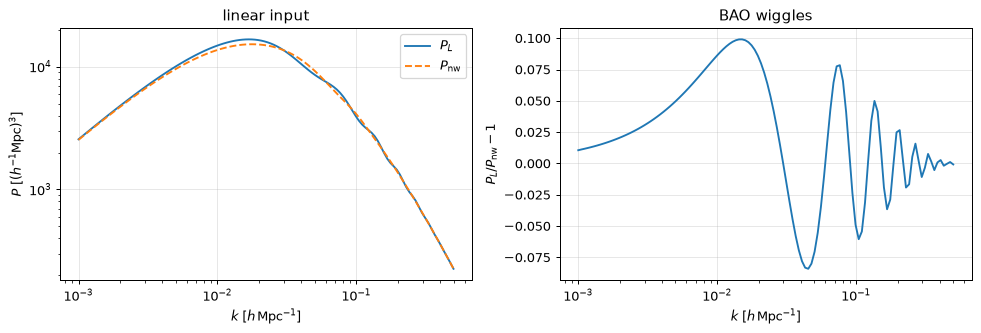

In [3]:
import hashlib
assert np.all(np.diff(k_in) > 0) and np.all(k_in > 0), "k must be positive and increasing"
assert np.all(np.isfinite(pk_in)) and np.all(pk_in > 0), "P(k) must be finite and positive"
sha_in = hashlib.sha256((REPO / "folps/inputpkT.txt").read_bytes()).hexdigest()[:16]
print(f"input range: k = {k_in[0]:.1e} .. {k_in[-1]:.2f} h/Mpc, {k_in.size} points, sha256 {sha_in}")
lin = nonlinear.get_linear(k_in, pk_in, cosmo=None, **cosmo)
kT, PL, Pnw = lin["k"], lin["pk_l"], lin["pk_l_NW"]
print(f"FolpsD output grid kTout: {kT[0]:.3f} .. {kT[-1]:.3f} h/Mpc, {kT.size} log points (template validity domain)")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].loglog(kT, PL, label=r"$P_L$"); ax[0].loglog(kT, Pnw, "--", label=r"$P_{\rm nw}$")
ax[0].set(xlabel=r"$k\ [h\,{\rm Mpc}^{-1}]$", ylabel=r"$P\ [(h^{-1}{\rm Mpc})^3]$", title="linear input"); ax[0].legend()
ax[1].semilogx(kT, PL / Pnw - 1); ax[1].set(xlabel=r"$k\ [h\,{\rm Mpc}^{-1}]$", ylabel=r"$P_L/P_{\rm nw}-1$", title="BAO wiggles")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "linear_input.png")

*Figure: linear spectrum and FolpsD's no-wiggle spectrum on the output grid (left), and the BAO wiggles (right).*

## 4. Standard FolpsD EFT baseline

`MatrixCalculator` builds cosmology-independent FFTLog matrices,
`NonLinearPowerSpectrumCalculator.calculate_loop_table` the full-shape and no-wiggle loop
tables, and `RSDMultipolesPowerSpectrumCalculator.get_rsd_pkell` the IR-resummed, AP-projected
multipoles. With `selection=None` this is exactly the pre-existing FolpsD code path.

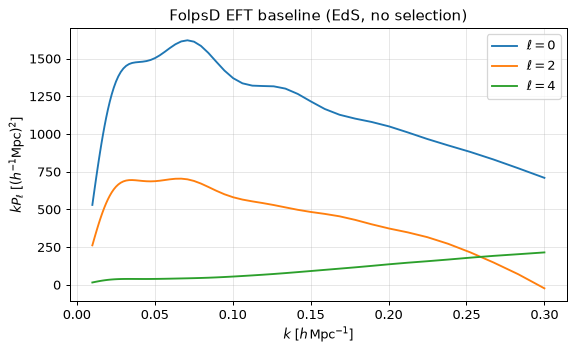

In [4]:
P0, P2, P4 = calc.get_rsd_pkell(kobs, 1.0, 1.0, pars, table, table_now, damping=None)
fig, ax = plt.subplots(figsize=(6.5, 4))
for P, l in zip((P0, P2, P4), (0, 2, 4)):
    ax.plot(kobs, kobs * P, label=fr"$\ell={l}$")
ax.set(xlabel=r"$k\ [h\,{\rm Mpc}^{-1}]$", ylabel=r"$k P_\ell\ [(h^{-1}{\rm Mpc})^2]$", title="FolpsD EFT baseline (EdS, no selection)")
ax.legend(); fig.tight_layout(); fig.savefig(OUTPUT_DIR / "baseline_multipoles.png")

*Figure: baseline EFT multipoles (no FoG damping; IR resummation on; unity AP).*

## 5. Bias conventions

The nine `SelectionBias` fields are **additional** coordinates that vanish without
selection. Internally the model uses the *mapped* DJS coefficients, which already include
the RSD Jacobian. Ordinary RSD is \(b_\eta=-1\), \(b_{\delta\eta}=-b_1\), \(b_{\eta^2}=1\), not zero.
The ordinary biases come from the legacy vector through `folps_bias_to_djs`
(\(b_{K^2}=b_{s^2}/2\), \(b_{3\rm nl}=-\frac{32}{21}(b_{K^2}+\frac25b_{\rm td})\)). The *rest-frame*
coefficients are those of the selected density before the RSD mapping.

In [5]:
b1d, b2d, bK2, btd = folps_bias_to_djs(*pars[:4])
c_sel = djs_coefficients(b1d, b2d, bK2, btd, selection)
c_std = djs_coefficients(b1d, b2d, bK2, btd, SelectionBias())
rest = rest_frame_coefficients(c_sel)
print(f"{'coefficient':18s} {'no selection':>13s} {'selected':>10s}   rest frame")
for (name, a), b, (rn, r) in zip(c_std._asdict().items(), c_sel, rest._asdict().items()):
    print(f"{name:18s} {a:13.4f} {b:10.4f}   {rn:18s} {r:8.4f}")

coefficient         no selection   selected   rest frame
b1                        1.6450     1.6450   b1                   1.6450
b_eta                    -1.0000    -0.8500   bR_eta               0.1500
b2                       -0.4600    -0.4600   b2                  -0.4600
b_K2                     -0.1843    -0.1843   b_K2                -0.1843
b_delta_eta              -1.6450    -1.9450   bR_delta_eta        -0.3000
b_eta2                    1.0000     1.2000   bR_eta2              0.3500
b_KK_par                  0.0000     0.4000   bR_KK_par            0.4000
b_Pi2_par                 0.0000    -0.5000   bR_Pi2_par          -0.5000
b_td                      0.3532     0.3532   b_td                 0.3532
b_delta_Pi2_par           0.0000     0.3000   bR_delta_Pi2_par     0.3000
b_eta_Pi2_par             0.0000    -0.2000   bR_eta_Pi2_par      -0.7000
b_KPi2_par                0.0000     0.3000   bR_KPi2_par          0.3000
b_Pi3_par                 0.0000     0.2000   bR_Pi3_pa

## 6. Linear intuition and the historical tree-only \(b_A\)

At linear order only \(s_\eta\) enters: \(Z_1=b_1-b_\eta f\mu^2=b_1+(1-s_\eta)f\mu^2\). The
historical tree-level traceless parameter \(b_A\) obeys the identity
\(b_{1,F}+f\mu^2+b_A(\mu^2-\tfrac13)=b_{1,D}-b_\eta f\mu^2\) with \(b_{1,D}=b_{1,F}-b_A/3\),
\(s_\eta=-b_A/f\). This identity says **nothing** about the quadratic and cubic
coefficients: a nonlinear model needs them specified separately.

[PASS] tree bA identity: max |diff| = 4.4e-16


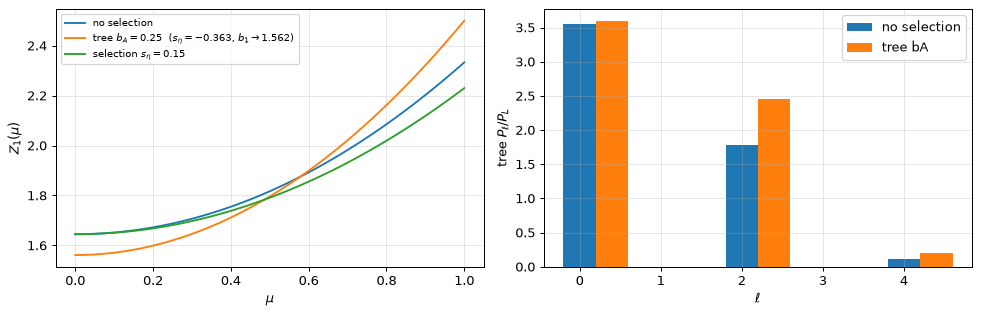

In [6]:
f0 = float(table[-1]); mu = np.linspace(0, 1, 101); bA = 0.25
b1D, s_eta_A = tree_bA_to_linear_djs(pars[0], bA, f0)
Z1_A = pars[0] + f0 * mu**2 + bA * (mu**2 - 1/3)
Z1_D = b1D - (-1 + s_eta_A) * f0 * mu**2
check("tree bA identity", np.max(abs(Z1_A - Z1_D)) < 1e-14, f"max |diff| = {np.max(abs(Z1_A - Z1_D)):.1e}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(mu, pars[0] + f0 * mu**2, label="no selection")
ax[0].plot(mu, Z1_A, label=fr"tree $b_A={bA}$  ($s_\eta={s_eta_A:.3f}$, $b_1\to{b1D:.3f}$)")
ax[0].plot(mu, c_sel.b1 - c_sel.b_eta * f0 * mu**2, label=fr"selection $s_\eta={selection.s_eta}$")
ax[0].set(xlabel=r"$\mu$", ylabel=r"$Z_1(\mu)$"); ax[0].legend(fontsize=8)
mu_gl, w_gl = np.polynomial.legendre.leggauss(16)
from scipy.special import eval_legendre
for lab, Z1fun in (("no selection", lambda m: pars[0] + f0*m**2), ("tree bA", lambda m: pars[0] + f0*m**2 + bA*(m**2-1/3))):
    coefs = [(2*l+1)/2*np.sum(w_gl*Z1fun(mu_gl)**2*eval_legendre(l, mu_gl)) for l in (0, 2, 4)]
    ax[1].bar(np.array([0, 2, 4]) + (0.4 if lab == "tree bA" else 0), coefs, width=0.4, label=lab)
ax[1].set(xlabel=r"$\ell$", ylabel=r"tree $P_\ell / P_L$"); ax[1].legend()
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "linear_intuition.png")

*Figure: linear kernel versus μ (left) and the tree-level multipole weights \(P_\ell/P_L\) (right).*

## 7. Quadratic kernels

The oracle `folps.selection_kernels` *generates* every kernel from its definition: the EdS
recursion, the convective tidal hierarchy, symmetrized products and LOS advection. We
evaluate \(Z_2\) at random triangles with a tilted LOS, check momentum-permutation and
LOS-reversal symmetry, check the hand-written ten-kernel table of the equation note, and
recover the standard redshift-space \(Z_2\) at zero selection.

[PASS] Z2 permutation + LOS reversal: 0.0e+00
[PASS] Z2 oracle vs ten-kernel table: 7.1e-15
[PASS] Z2 mapped field vs exact rest-frame map: 3.6e-15
[PASS] Z2 at zero selection = standard RSD Z2: 3.6e-15


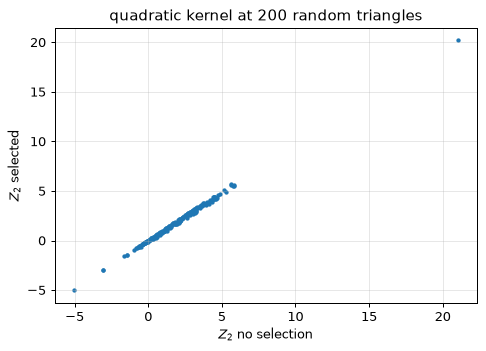

In [7]:
from folps.selection_reference import mapped_field, exact_map_field_from_djs
rng = np.random.default_rng(7)
k1, k2 = rng.normal(size=(200, 3)), rng.normal(size=(200, 3))
nlos = rng.normal(size=(200, 3)); nlos /= np.linalg.norm(nlos, axis=1, keepdims=True)
ev = sk.Evaluator([k1, k2], nlos, f0)
Z2 = mapped_field(c_sel._asdict()).at(ev, 2).real
Z2_swap = mapped_field(c_sel._asdict()).at(sk.Evaluator([k2, k1], -nlos, f0), 2).real
S = sk.quadratic_table_kernels(k1, k2, nlos, f0)
from folps.selection_operators import quadratic_coefficient_vector
Z2_table = np.einsum("a,a...->...", np.array(quadratic_coefficient_vector(c_sel, galilean_safe=False)), S)
Z2_exactmap = exact_map_field_from_djs(c_sel._asdict()).at(ev, 2).real
check("Z2 permutation + LOS reversal", np.max(abs(Z2 - Z2_swap)) < 1e-12, f"{np.max(abs(Z2 - Z2_swap)):.1e}")
check("Z2 oracle vs ten-kernel table", np.max(abs(Z2 - Z2_table)) < 1e-12, f"{np.max(abs(Z2 - Z2_table)):.1e}")
check("Z2 mapped field vs exact rest-frame map", np.max(abs(Z2 - Z2_exactmap)) < 1e-12, f"{np.max(abs(Z2 - Z2_exactmap)):.1e}")
Z20 = mapped_field(c_std._asdict()).at(ev, 2).real
kn1, kn2 = np.linalg.norm(k1, axis=1), np.linalg.norm(k2, axis=1); K = k1 + k2; Kn = np.linalg.norm(K, axis=1)
mu1, mu2, muK = np.sum(k1*nlos, 1)/kn1, np.sum(k2*nlos, 1)/kn2, np.sum(K*nlos, 1)/Kn
nu = np.sum(k1*k2, 1)/kn1/kn2
Zstd = (b1d*sk.F2_closed_form(k1, k2) + f0*muK**2*sk.G2_closed_form(k1, k2) + b2d/2 + bK2*(nu**2 - 1/3)
        + f0*Kn*muK/2*(mu1/kn1*(b1d + f0*mu2**2) + mu2/kn2*(b1d + f0*mu1**2)))
check("Z2 at zero selection = standard RSD Z2", np.max(abs(Z20 - Zstd)) < 1e-12, f"{np.max(abs(Z20 - Zstd)):.1e}")
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(Z20, Z2, s=6); ax.set(xlabel=r"$Z_2$ no selection", ylabel=r"$Z_2$ selected", title="quadratic kernel at 200 random triangles")
fig.tight_layout()

*Figure: the selected and unselected quadratic kernels at the same random configurations.*

## 8. Selection templates

`build_selection_tables(nonlinear)` reuses the calculator's extrapolated spectra and FFTLog
coefficients. It returns named full-shape and no-wiggle `SelectionLoopTable`s containing
the 23 P22 functions \(\mathcal I_{mr}(k)\) at two FFTLog tilts, the five P13 functions
\(J_n(k)\), \(\sigma_{-1}^2\) and metadata. The cosmology-independent matrices are cached in
memory and in `CACHE_DIR` under a key that includes the generator version, coefficient
checksum, grid, tilt and dtype. Nuisance and selection parameters only enter the final
contraction, so changing them never rebuilds a table.

In [8]:
T = sel_tables.full
print(sel_tables)
print("I22:", T.I22.shape, "(tilt class, 23 basis functions, k) [(Mpc/h)^3];  J13:", T.J13.shape, "dimensionless")
print(f"sigma_-1^2 = {T.sigma_m1_sq:.3f} (Mpc/h)^2 ;  f0 = {T.f0:.4f}")
print("P22 basis (m, r):", sc.P22_BASIS)
for key in ("kernels", "template_format", "generator", "nfftlog", "b_nu", "p22_tilt_local", "k_min", "k_max", "template_key"):
    print(f"  {key:16s} {T.metadata[key]}")
t0 = time.perf_counter(); build_selection_tables(nonlinear); t_tab = time.perf_counter() - t0
sel2 = selection._replace(s_KK_par=0.0)
t0 = time.perf_counter()
for _ in range(10):
    calc.get_rsd_pkell(kobs, 1.0, 1.0, pars, table, table_now, damping=None, selection=sel2, selection_tables=sel_tables)
t_eval = (time.perf_counter() - t0) / 10
print(f"template rebuild (warm matrices): {t_tab*1e3:.1f} ms;  multipoles with new selection values: {t_eval*1e3:.1f} ms")

SelectionLoopTables(full=SelectionLoopTable(role='full', nk=120, I22=(2, 23, 120), J13=(5, 120), kernels='EdS', key='19cb1a3dd10d2a8e'), nowiggle=SelectionLoopTable(role='nowiggle', nk=120, I22=(2, 23, 120), J13=(5, 120), kernels='EdS', key='cdb4a9deb780c390'))
I22: (2, 23, 120) (tilt class, 23 basis functions, k) [(Mpc/h)^3];  J13: (5, 120) dimensionless
sigma_-1^2 = 72.089 (Mpc/h)^2 ;  f0 = 0.6881
P22 basis (m, r): ((0, 0), (0, 2), (0, 4), (0, 6), (1, 1), (1, 3), (1, 5), (2, 0), (2, 2), (2, 4), (2, 6), (3, 1), (3, 3), (3, 5), (4, 2), (4, 4), (4, 6), (5, 3), (5, 5), (6, 4), (6, 6), (7, 5), (8, 6))
  kernels          EdS
  template_format  selection-template-2
  generator        selection-eds-gen-1.0
  nfftlog          128
  b_nu             -0.1
  p22_tilt_local   -0.9
  k_min            0.001
  k_max            0.5
  template_key     19cb1a3dd10d2a8e


template rebuild (warm matrices): 51.8 ms;  multipoles with new selection values: 55.2 ms


## 9. The full selected model

A generic selection with all four quadratic and all four cubic coordinates nonzero
(`selection` above). The prediction is the FolpsD baseline at the *same* ordinary biases
plus selected-minus-unselected increments of the tree and of the complete one-loop
spectrum, mixed with the same IR prescription.

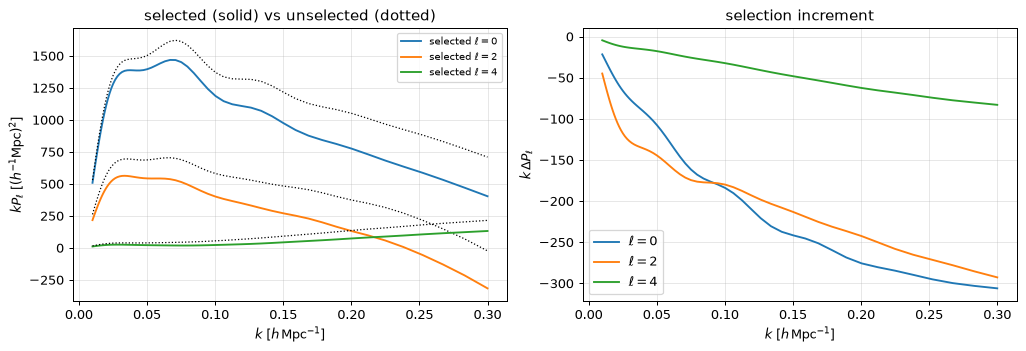

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
for P, Q, l in zip(P_sel, P_std, (0, 2, 4)):
    ax[0].plot(kobs, kobs * P, label=fr"selected $\ell={l}$")
    ax[0].plot(kobs, kobs * Q, "k:", lw=1)
    ax[1].plot(kobs, kobs * (P - Q), label=fr"$\ell={l}$")
ax[0].set(xlabel=r"$k\ [h\,{\rm Mpc}^{-1}]$", ylabel=r"$kP_\ell\ [(h^{-1}{\rm Mpc})^2]$", title="selected (solid) vs unselected (dotted)")
ax[1].set(xlabel=r"$k\ [h\,{\rm Mpc}^{-1}]$", ylabel=r"$k\,\Delta P_\ell$", title="selection increment"); ax[0].legend(fontsize=8); ax[1].legend()
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "selected_multipoles.png")

*Figure: selected multipoles (left) and the increment with respect to the unselected prediction at identical ordinary biases (right).*

## 10. Spectrum components

`return_components=True` returns the pieces of the prediction. `tree` and `loop` are the
totals actually used. `P22_templates` and `P13_templates` show the full selected 22 and 13
contributions computed from the templates alone (IR-mixed). The scheme: **P22** has only its
zero-lag constant removed (it is absorbed into the shot noise); **P13** is *bare*. It keeps
the \(k^2\sigma^2\) terms that cancel the infrared sensitivity of P22, and drops only the
constant \(\sigma_0^2\) pieces, which renormalize \(b_1\) and \(b_\eta\).

scheme: P22: zero-lag constant subtracted; P13: bare k^2 sigma^2 kept, sigma_0^2 constants renormalized


[PASS] components add up to total: 


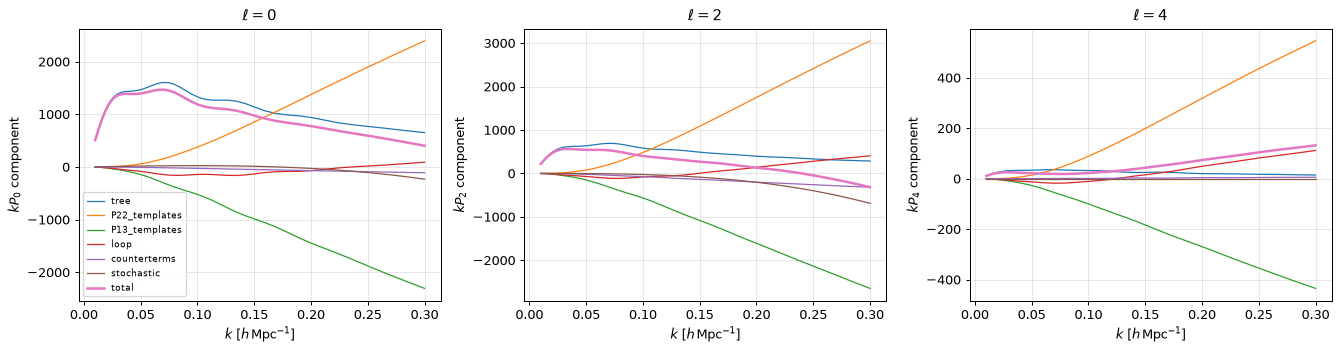

In [10]:
comp = calc.get_rsd_pkell(kobs, 1.0, 1.0, pars, table, table_now, damping=None, selection=selection,
                          selection_tables=sel_tables, return_components=True)
print("scheme:", comp["scheme"])
names = ("tree", "P22_templates", "P13_templates", "loop", "counterterms", "stochastic", "total")
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for i, l in enumerate((0, 2, 4)):
    for n in names:
        axs[i].plot(kobs, kobs * comp[n][i], label=n, lw=2 if n == "total" else 1)
    axs[i].set(xlabel=r"$k\ [h\,{\rm Mpc}^{-1}]$", ylabel=fr"$k P_{l}$ component", title=fr"$\ell={l}$")
axs[0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "components.png")
recon = comp["tree_baseline"] + comp["loop_baseline"] + comp["counterterms"] + comp["stochastic"] + comp["ctilde"] \
        + comp["delta_tree"] + comp["delta_loop"] + comp["delta_ctilde"]
check("components add up to total", np.allclose(recon, comp["total"], rtol=1e-12, atol=1e-8), "")

*Figure: components of the selected multipoles. The P22 and P13 template curves are the full selected loop pieces; `loop` is the total loop (FolpsD baseline loop plus selection increment).*

## 11. Model comparison at matched linear kernel

Three models with the same \(Z_1(\mu)\): (a) the unselected baseline with
\(b_1\to b_{1,F}\); (b) the historical **tree-only** \(b_A\) (it changes only the resummed tree);
(c) the full one-loop model with the linear coordinates of (b), i.e.
\(b_1=b_{1,F}-b_A/3\), \(s_\eta=-b_A/f\), and the stated convention that **all nonlinear
selection coefficients vanish**. (c) differs from (b) through the selected loops: the
nonlinear response to a change of \(b_\eta\) at fixed ordinary nonlinear biases. Any other
convention for the nonlinear coefficients (e.g. coevolution) gives a different (c).

max |(c)-(b)| / max|P_ell|: [0.004309138812704861, 0.019109476285348, 0.07330968051004479]


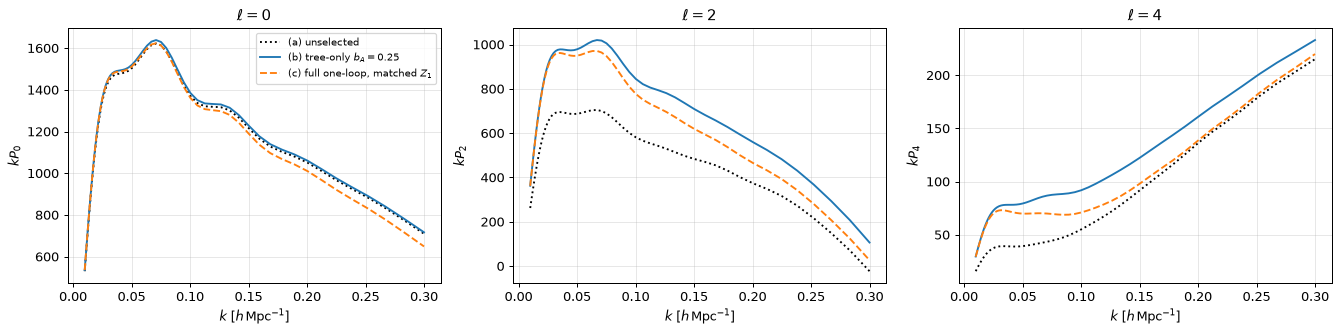

In [11]:
def pkell_bA(bA_):
    # historical tree-only model through the legacy bA argument (P(k,mu) level, projected here)
    muobs, w = np.polynomial.legendre.leggauss(12)
    muobs, w = muobs[6:], (w[6:] + w[5::-1]) / 2
    kk = kobs[:, None] * np.ones((1, muobs.size)); mm = np.ones((kobs.size, 1)) * muobs[None, :]
    pkmu = calc.get_rsd_pkmu(kk, mm, pars, table, table_now, damping=None, bA=bA_)
    return np.array([np.sum(pkmu * w * (2*l + 1) * eval_legendre(l, muobs), axis=-1) for l in (0, 2, 4)])
P_b = pkell_bA(bA)
pars_c = list(pars); pars_c[0] = b1D
P_c = calc.get_rsd_pkell(kobs, 1.0, 1.0, pars_c, table, table_now, damping=None,
                         selection=SelectionBias(s_eta=s_eta_A), selection_tables=sel_tables)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for i, l in enumerate((0, 2, 4)):
    axs[i].plot(kobs, kobs * P_std[i], "k:", label="(a) unselected")
    axs[i].plot(kobs, kobs * P_b[i], label=fr"(b) tree-only $b_A={bA}$")
    axs[i].plot(kobs, kobs * P_c[i], "--", label="(c) full one-loop, matched $Z_1$")
    axs[i].set(xlabel=r"$k\ [h\,{\rm Mpc}^{-1}]$", ylabel=fr"$kP_{l}$", title=fr"$\ell={l}$")
axs[0].legend(fontsize=8); fig.tight_layout(); fig.savefig(OUTPUT_DIR / "model_comparison.png")
print("max |(c)-(b)| / max|P_ell|:", [float(np.max(abs(P_c[i] - P_b[i])) / np.max(abs(P_b[i]))) for i in range(3)])

*Figure: unselected, historical tree-only \(b_A\), and full one-loop selection with the matched linear kernel (nonlinear selection coefficients set to zero).*

## 12. Parameter responses

One-at-a-time responses \(\partial P_\ell/\partial s_O\) for the nine coordinates, at \(\mathbf s=0\)
and at the generic point. The prediction is at most **quadratic** in the selection
coordinates: P22 is quadratic in the quadratic coefficients, and \(s_\eta\) also enters the
tree, \(Z_1\) (which multiplies P13) and P22. Central differences with a finite step are
therefore exact up to round-off. For a coordinate that enters only quadratically the
derivative at zero can vanish. Here every coordinate has a nonzero first derivative at
zero, because each interferes with the ordinary bias and RSD kernels. The curvature panel
shows the purely quadratic part \(P(s)-P(0)-s\,\partial_sP(0)\).

[PASS] cubic coordinates enter linearly: curvature/response < 1e-8 for the four cubic coordinates


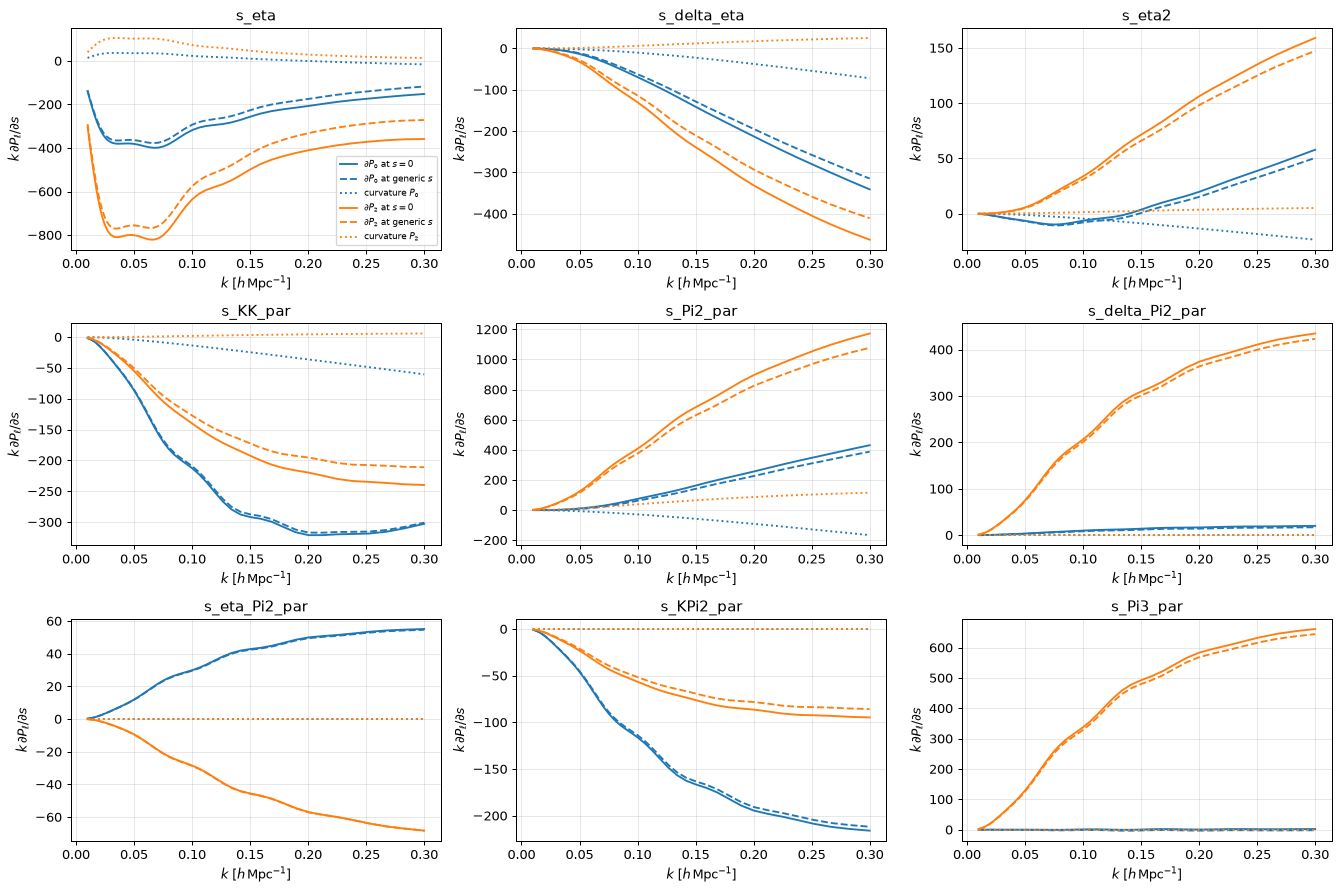

In [12]:
def pell(sel_, pars_=pars, **kw):
    return calc.get_rsd_pkell(kobs, 1.0, 1.0, pars_, table, table_now, damping=None, selection=sel_,
                              selection_tables=sel_tables, **kw)
fields = SelectionBias._fields
h = 0.1
resp0, resp1, curv = {}, {}, {}
for fld in fields:
    e = SelectionBias(**{fld: h})
    resp0[fld] = (pell(e) - pell(SelectionBias(**{fld: -h}))) / (2 * h)
    sp_ = selection._replace(**{fld: getattr(selection, fld) + h}); sm_ = selection._replace(**{fld: getattr(selection, fld) - h})
    resp1[fld] = (pell(sp_) - pell(sm_)) / (2 * h)
    one = SelectionBias(**{fld: 1.0})
    curv[fld] = pell(one) - pell(SelectionBias()) - resp0[fld]
fig, axs = plt.subplots(3, 3, figsize=(15, 10))
for ax, fld in zip(axs.ravel(), fields):
    for i, l in enumerate((0, 2)):
        ax.plot(kobs, kobs * resp0[fld][i], f"C{i}", label=fr"$\partial P_{l}$ at $s=0$")
        ax.plot(kobs, kobs * resp1[fld][i], f"C{i}--", label=fr"$\partial P_{l}$ at generic $s$")
        ax.plot(kobs, kobs * curv[fld][i], f"C{i}:", label=fr"curvature $P_{l}$")
    ax.set(title=fld, xlabel=r"$k\ [h\,{\rm Mpc}^{-1}]$", ylabel=r"$k\,\partial P_\ell/\partial s$")
axs[0, 0].legend(fontsize=7); fig.tight_layout(); fig.savefig(OUTPUT_DIR / "parameter_responses.png")
lin_cubic = all(np.max(abs(curv[f_])) < 1e-8 * np.max(abs(resp0[f_])) for f_ in fields[5:])
check("cubic coordinates enter linearly", lin_cubic, "curvature/response < 1e-8 for the four cubic coordinates")

*Figure: responses of \(P_0\) and \(P_2\) to each selection coordinate at \(\mathbf s=0\) (solid) and at the generic point (dashed), and the purely quadratic part (dotted; zero for the cubic coordinates, which enter only through P13).*

## 13. IR resummation and the wiggle loop

IR off versus on, and the split of the loop into smooth and wiggle parts. The wiggle loop
used by the model is \(L[P_L]-L[P_{\rm nw}]\). The "loop of the wiggles alone" \(L[P_w]\) misses
the smooth×wiggle cross terms (the loop is quadratic in \(P\)). It is computed here only to
show the difference and is **not** used anywhere in the prediction.

max |L[P_L]-L[P_nw] - L[P_w]| / max|L[P_L]-L[P_nw]| = 1.0015602483700736


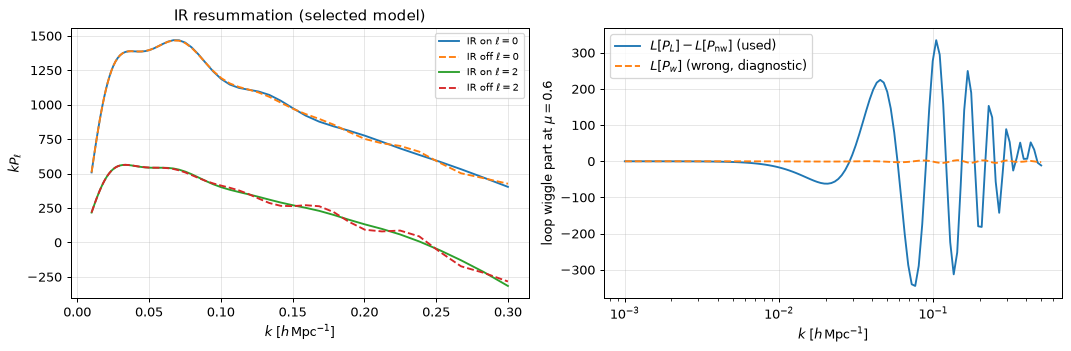

In [13]:
P_noIR = calc.get_rsd_pkell(kobs, 1.0, 1.0, pars, table, table_now, damping=None, IR_resummation=False,
                            selection=selection, selection_tables=sel_tables)
from folps.selection_templates import selection_loop
import copy
from folps.folps import get_cm
mu6 = np.full_like(T.k, 0.6)
L_full = sum(selection_loop(T.k, mu6, sel_tables.full, c_sel))
L_nw = sum(selection_loop(T.k, mu6, sel_tables.nowiggle, c_sel))
# loop of the wiggles alone (diagnostic only): tables from P_w = P_L - P_nw on the same grids
nlw = copy.copy(nonlinear)
qq, Pw = nonlinear.inputpkT[0], nonlinear.inputpkT[1] - nonlinear.inputpkT_NW[1]
nlw.inputpkT = (qq, Pw); nlw.pk_l = nonlinear.pk_l - nonlinear.pk_l_NW
nlw.cmT = get_cm(nonlinear.kmin, nonlinear.kmax, nonlinear.nfftlog, nonlinear.b_nu, (qq, Pw))
L_w = sum(selection_loop(T.k, mu6, build_selection_tables(nlw).full, c_sel))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for P, Q, l in zip(P_sel, P_noIR, (0, 2)):
    ax[0].plot(kobs, kobs * P, label=fr"IR on $\ell={l}$"); ax[0].plot(kobs, kobs * Q, "--", label=fr"IR off $\ell={l}$")
ax[0].set(xlabel=r"$k\ [h\,{\rm Mpc}^{-1}]$", ylabel=r"$kP_\ell$", title="IR resummation (selected model)"); ax[0].legend(fontsize=8)
ax[1].plot(T.k, L_full - L_nw, label=r"$L[P_L]-L[P_{\rm nw}]$ (used)")
ax[1].plot(T.k, L_w, "--", label=r"$L[P_w]$ (wrong, diagnostic)")
ax[1].set(xscale="log", xlabel=r"$k\ [h\,{\rm Mpc}^{-1}]$", ylabel=r"loop wiggle part at $\mu=0.6$"); ax[1].legend()
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "ir_resummation.png")
print("max |L[P_L]-L[P_nw] - L[P_w]| / max|L[P_L]-L[P_nw]| =", float(np.max(abs(L_full - L_nw - L_w)) / np.max(abs(L_full - L_nw))))

*Figure: IR on/off for the selected model (left); the wiggle part of the selected loop versus the incorrect loop-of-wiggles (right).*

In [14]:
# one-loop re-expansion: with IR on, P_IR(sel) - P_IR(nosel) must equal the IR-mixed tree and loop
# increments, and selection must not enter the displacement variance Sigma_s^2(mu)
kk = kobs[:, None] * np.ones((1, 3)); mm_ = np.array([0.2, 0.6, 0.9])[None, :] * np.ones((kobs.size, 1))
c_on = calc.get_rsd_pkmu(kk, mm_, pars, table, table_now, damping=None, selection=selection, selection_tables=sel_tables, return_components=True)
c_off = calc.get_rsd_pkmu(kk, mm_, pars, table, table_now, damping=None, return_components=True)
inc = c_on["total"] - c_off["total"]
check("IR: selected - unselected = mixed increments", np.allclose(inc, c_on["delta_tree"] + c_on["delta_loop"] + c_on["delta_ctilde"], rtol=1e-10, atol=1e-8), "")

[PASS] IR: selected - unselected = mixed increments: 


## 14. Derivative and noise sectors

Optional extensions (`EFTExtension`): \(\alpha_6\mu^6k^2P_L\), an isotropic \(k^2\) noise
\(P_{\rm shot}\alpha^{\rm iso}_{\rm shot,2}k^2\), and a *proposed* \(P_{\rm shot}\alpha^{\mu^4}_{\rm shot,2}k^2\mu^4\)
term (see the validation report: the UV-sensitive \(k^2\) part of the selected P22 has a
\(\mu^4\) piece). The alternative **physical derivative** mode (`PhysicalDerivativeBias`)
*replaces* the polynomial counterterms with the DJS form. Below: the conversion check and
the rank of the counterterm templates in \((P_0,P_2,P_4)\). Without IR resummation the four
\(k^2\mu^{2r}P_L\) templates span only three directions for \(\ell\le4\); with IR the \(\mu^6\) template
gains a small independent component.

In [15]:
from folps import physical_to_polynomial_derivatives
phys = PhysicalDerivativeBias(b_nabla2delta=1.0, beta_nabla2v=-0.5, beta_par2v=0.3)
p0 = list(pars); p0[4] = p0[5] = p0[6] = 0.0
Pphys = calc.get_rsd_pkell(kobs, 1.0, 1.0, p0, table, table_now, damping=None, selection=selection,
                           selection_tables=sel_tables, physical_derivatives=phys)
cc = physical_to_polynomial_derivatives(c_sel.b1, c_sel.b_eta, f0, phys)
p1 = list(pars); p1[4], p1[5], p1[6] = cc[:3]
Ppoly = calc.get_rsd_pkell(kobs, 1.0, 1.0, p1, table, table_now, damping=None, selection=selection,
                           selection_tables=sel_tables, eft_extension=EFTExtension(alpha6=cc[3]))
check("physical derivative mode = converted polynomial", np.allclose(Pphys, Ppoly, rtol=1e-12), f"(c0,c2,c4,c6) = {np.round(cc, 3)}")
try:
    calc.get_rsd_pkell(kobs, 1.0, 1.0, pars, table, table_now, damping=None, physical_derivatives=phys)
    check("double derivative parameterization rejected", False, "no error")
except ValueError as err:
    check("double derivative parameterization rejected", True, str(err)[:70])
from folps.selection_model import selected_pkell_linear_decomposition
for ir in (False, True):
    _, temps, names_ = selected_pkell_linear_decomposition(calc, kobs, 1.0, 1.0, pars, table, table_now, IR_resummation=ir,
                                                           selection=selection, selection_tables=sel_tables, eft_extension=EFTExtension())
    A_ = np.stack([temps[i].ravel() / np.linalg.norm(temps[i]) for i in (0, 1, 2, 5)])   # alpha0, alpha2, alpha4, alpha6
    sv = np.linalg.svd(A_, compute_uv=False)
    print(f"IR={ir}: singular values of normalized (alpha0, alpha2, alpha4, alpha6) templates in (P0,P2,P4):", np.array2string(sv, precision=3))

[PASS] physical derivative mode = converted polynomial: (c0,c2,c4,c6) = [-3.29  -0.208 -0.235 -0.205]
[PASS] double derivative parameterization rejected: physical_derivatives replaces the polynomial counterterms; alpha0 must


IR=False: singular values of normalized (alpha0, alpha2, alpha4, alpha6) templates in (P0,P2,P4): [1.731e+00 9.304e-01 3.720e-01 2.907e-13]


IR=True: singular values of normalized (alpha0, alpha2, alpha4, alpha6) templates in (P0,P2,P4): [1.731e+00 9.305e-01 3.721e-01 1.130e-04]


## 15. Alcock–Paczynski projection

For \(q_\parallel,q_\perp\neq1\) the true \((k,\mu)\) are computed from the observed ones and the
spectrum is divided by \(q_\parallel q_\perp^2\). The selected model goes through the same mapping as
the legacy one. The true \(k\) must stay inside the template domain
(\(0.001\le k\le0.5\,h/\)Mpc), which we check.

[PASS] AP true-k inside template domain: k_true in [0.0096, 0.3093] vs [0.001, 0.5]
[PASS] AP mapping and 1/(qpar qper^2) volume factor (selected model): max rel diff per ell [5.8e-09 3.6e-08 9.2e-07]


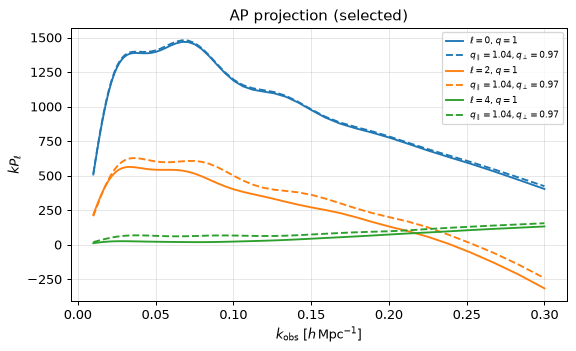

In [16]:
qpar, qper = 1.04, 0.97
muobs = np.linspace(0, 1, 50)
kap = calc.k_ap(kobs[:, None], muobs[None, :], qpar, qper)
check("AP true-k inside template domain", (kap.min() >= T.k[0]) and (kap.max() <= T.k[-1]),
      f"k_true in [{kap.min():.4f}, {kap.max():.4f}] vs [{T.k[0]}, {T.k[-1]}]")
P_ap = calc.get_rsd_pkell(kobs, qpar, qper, pars, table, table_now, damping=None, selection=selection, selection_tables=sel_tables)
# explicit mapping + volume factor: P_ell(k_obs) = (2l+1)/2 int dmu_obs L_l(mu_obs) P(k(k_obs,mu_obs), mu(mu_obs)) / (qpar qper^2)
mu_full, w_full = np.polynomial.legendre.leggauss(64)
kk_ = kobs[:, None] * np.ones((1, mu_full.size))
pk_true = calc.get_rsd_pkmu(calc.k_ap(kk_, mu_full[None, :], qpar, qper), calc.mu_ap(mu_full, qpar, qper)[None, :] * np.ones_like(kk_),
                            pars, table, table_now, damping=None, selection=selection, selection_tables=sel_tables)
P_manual = np.array([(2*l + 1) / 2 * np.sum(w_full * eval_legendre(l, mu_full) * pk_true, axis=-1) / (qpar * qper**2) for l in (0, 2, 4)])
err_ap = np.max(np.abs(P_manual - P_ap), axis=1) / np.max(np.abs(P_ap), axis=1)
check("AP mapping and 1/(qpar qper^2) volume factor (selected model)", np.all(err_ap < 1e-5), f"max rel diff per ell {np.array2string(err_ap, precision=1)}")
fig, ax = plt.subplots(figsize=(6.5, 4))
for P, Q, l in zip(P_sel, P_ap, (0, 2, 4)):
    ax.plot(kobs, kobs * P, f"C{l//2}", label=fr"$\ell={l}$, $q=1$"); ax.plot(kobs, kobs * Q, f"C{l//2}--", label=fr"$q_\parallel={qpar},q_\perp={qper}$")
ax.set(xlabel=r"$k_{\rm obs}\ [h\,{\rm Mpc}^{-1}]$", ylabel=r"$kP_\ell$", title="AP projection (selected)"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "ap_projection.png")

*Figure: selected multipoles at unity AP (solid) and for \(q_\parallel=1.04, q_\perp=0.97\) (dashed).*

## 16. Angular convergence

`get_rsd_pkell(nmu=n)` uses \(n\) Gauss–Legendre nodes on \([0,1]\) obtained by symmetrizing a
\(2n\)-node full-range rule (\(P(k,\mu)\) is even in \(\mu\)), exact for polynomial integrands of
degree \(\le4n-1\). Without IR and at unity AP the selected \(P(k,\mu)\) is a polynomial of degree 8
in \(\mu\), so the \(\ell=4\) projection integrand has degree 12 and is exact for \(n\ge4\). With IR
resummation or AP it is not a polynomial. We compare \(n=3,6,12,24,48\) (6–96 full-range nodes)
with \(n=96\).

nmu=  3: max|P_ell - P_ell(96)| / max|P_ell| = [4.12e-07 2.16e-05 3.22e-03]
nmu=  6: max|P_ell - P_ell(96)| / max|P_ell| = [5.77e-09 3.60e-08 9.15e-07]
nmu= 12: max|P_ell - P_ell(96)| / max|P_ell| = [3.99e-10 1.52e-09 4.00e-08]
nmu= 24: max|P_ell - P_ell(96)| / max|P_ell| = [2.98e-11 1.08e-10 2.44e-09]


nmu= 48: max|P_ell - P_ell(96)| / max|P_ell| = [2.53e-12 8.24e-12 2.17e-10]


[PASS] default nmu=6 angular error < 1e-4: 
IR=False, AP=(1.0, 1.0): max|P_ell|/max|P_0| for ell=0..8: [1.00e+00 4.24e-01 2.14e-02 8.80e-04 4.76e-05] ; 12-node error: [5.0e-15 1.7e-13 6.5e-12 2.3e-10 5.5e-09]


IR=True, AP=(1.04, 0.97): max|P_ell|/max|P_0| for ell=0..8: [1.00e+00 4.20e-01 4.16e-02 2.60e-03 1.83e-04] ; 12-node error: [5.8e-09 3.6e-08 9.2e-07 2.5e-05 7.3e-04]


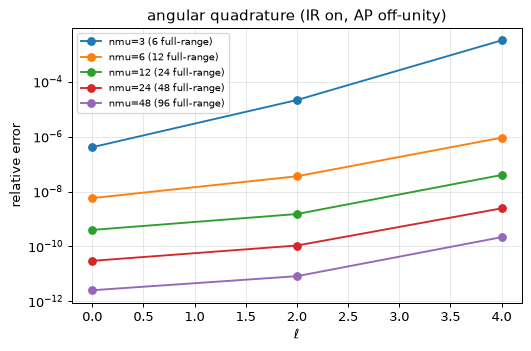

In [17]:
ref_mu = calc.get_rsd_pkell(kobs, qpar, qper, pars, table, table_now, damping=None, nmu=96, selection=selection, selection_tables=sel_tables)
scale_ = np.max(np.abs(ref_mu), axis=1)
fig, ax = plt.subplots(figsize=(6, 4))
for n in (3, 6, 12, 24, 48):
    P_n = calc.get_rsd_pkell(kobs, qpar, qper, pars, table, table_now, damping=None, nmu=n, selection=selection, selection_tables=sel_tables)
    err = np.max(np.abs(P_n - ref_mu), axis=1) / scale_
    ax.semilogy([0, 2, 4], np.maximum(err, 1e-17), "o-", label=f"nmu={n} ({2*n} full-range)")
    print(f"nmu={n:3d}: max|P_ell - P_ell(96)| / max|P_ell| =", np.array2string(err, precision=2))
ax.set(xlabel=r"$\ell$", ylabel="relative error", title="angular quadrature (IR on, AP off-unity)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "angular_convergence.png")
P6 = calc.get_rsd_pkell(kobs, qpar, qper, pars, table, table_now, damping=None, nmu=6, selection=selection, selection_tables=sel_tables)
check("default nmu=6 angular error < 1e-4", np.all(np.max(np.abs(P6 - ref_mu), axis=1) / scale_ < 1e-4), "")
# ell = 6, 8 diagnostics.  FolpsD's legendre() helper only provides ell <= 4, so project
# get_rsd_pkmu directly (Gauss-Legendre over [-1, 1]; 12 nodes = the default nmu=6 rule).
def project(ells_, nfull, qp_, qq_, ir_):
    x_, w_ = np.polynomial.legendre.leggauss(nfull)
    kk2 = kobs[:, None] * np.ones((1, nfull))
    pk_ = calc.get_rsd_pkmu(calc.k_ap(kk2, x_[None, :], qp_, qq_), calc.mu_ap(x_, qp_, qq_)[None, :] * np.ones_like(kk2),
                            pars, table, table_now, IR_resummation=ir_, damping=None, selection=selection, selection_tables=sel_tables)
    return np.array([(2*l + 1) / 2 * np.sum(w_ * eval_legendre(l, x_) * pk_, axis=-1) / (qp_ * qq_**2) for l in ells_])
ells_hi = (0, 2, 4, 6, 8)
for ir_, (qp_, qq_) in ((False, (1.0, 1.0)), (True, (qpar, qper))):
    hi_ref, hi_12 = project(ells_hi, 192, qp_, qq_, ir_), project(ells_hi, 12, qp_, qq_, ir_)
    ratio = np.max(np.abs(hi_ref), axis=1) / np.max(np.abs(hi_ref[0]))
    err = np.max(np.abs(hi_12 - hi_ref), axis=1) / np.max(np.abs(hi_ref), axis=1)
    print(f"IR={ir_}, AP={(qp_, qq_)}: max|P_ell|/max|P_0| for ell=0..8:", np.array2string(ratio, precision=2),
          "; 12-node error:", np.array2string(err, precision=1))

## 17. Zero-selection regression

The frozen pre-edit reference `tests/data/eft_baseline_reference.npz` was produced by the
*unmodified* upstream code. The legacy call (`selection=None`) and an **explicit zero**
`SelectionBias()` are compared with it. The explicit zero runs the complete selection
machinery: its increments are computed and are exactly zero. They are not skipped by a
conditional.

IR    AP     legacy vs frozen   zero vs frozen  bitwise equal
True  ap1            0.00e+00         0.00e+00           True
True  ap2            0.00e+00         0.00e+00           True
False ap1            0.00e+00         0.00e+00           True
False ap2            0.00e+00         0.00e+00           True
[PASS] legacy and explicit zero reproduce frozen baseline: max rel diff <= 1e-12, bitwise equal


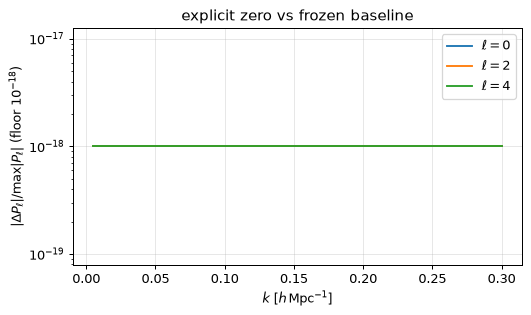

In [18]:
frozen = np.load(REPO / "tests" / "data" / "eft_baseline_reference.npz")
rows = []
for ir in (True, False):
    for tag, (qp, qq_) in (("ap1", (1.0, 1.0)), ("ap2", (1.03, 0.98))):
        ref = frozen[f"pell_EdS_ir{int(ir)}_{tag}"]
        leg = calc.get_rsd_pkell(frozen["kobs"], qp, qq_, list(frozen["pars"]), table, table_now, damping=None, IR_resummation=ir)
        zer = calc.get_rsd_pkell(frozen["kobs"], qp, qq_, list(frozen["pars"]), table, table_now, damping=None, IR_resummation=ir,
                                 selection=SelectionBias(), selection_tables=sel_tables)
        rows.append((ir, tag, np.max(abs(leg - ref)) / np.max(abs(ref)), np.max(abs(zer - ref)) / np.max(abs(ref)), np.array_equal(leg, zer)))
print(f"{'IR':5s} {'AP':4s} {'legacy vs frozen':>18s} {'zero vs frozen':>16s} {'bitwise equal':>14s}")
for r in rows:
    print(f"{str(r[0]):5s} {r[1]:4s} {r[2]:18.2e} {r[3]:16.2e} {str(r[4]):>14s}")
check("legacy and explicit zero reproduce frozen baseline", all(r[2] <= 1e-12 and r[3] <= 1e-12 and r[4] for r in rows), "max rel diff <= 1e-12, bitwise equal")
fig, ax = plt.subplots(figsize=(6, 3.6))
d = np.abs(calc.get_rsd_pkell(frozen["kobs"], 1.0, 1.0, list(frozen["pars"]), table, table_now, damping=None, selection=SelectionBias(),
                               selection_tables=sel_tables) - frozen["pell_EdS_ir1_ap1"])
for i in range(3):
    ax.semilogy(frozen["kobs"], np.maximum(d[i] / np.max(abs(frozen["pell_EdS_ir1_ap1"][i])), 1e-18), label=fr"$\ell={2*i}$")
ax.set(xlabel=r"$k\ [h\,{\rm Mpc}^{-1}]$", ylabel=r"$|\Delta P_\ell|/\max|P_\ell|$ (floor $10^{-18}$)", title="explicit zero vs frozen baseline")
ax.legend(); fig.tight_layout()

*Figure: explicit zero selection minus the frozen pre-edit baseline, relative to \(\max|P_\ell|\). All values sit at the plotting floor because the difference is exactly zero.*

## 18. Independent nonzero-selection test

The fast FFTLog templates are compared with a **direct quadrature** of the same physics:
oracle kernels from the field algebra, the exact redshift-space map, and full radial, polar
and azimuthal integrals, with no FFTLog and no generated coefficients. The comparison uses
all nine coordinates nonzero, at FolpsD grid points. The shipped fixture
`tests/data/selection_reference_fixture.npz` contains the direct-quadrature values;
`scripts/validate_selection_reference.py` regenerates it. With `RUN_SLOW_VALIDATION` one
point is recomputed here.

In [19]:
fx = np.load(REPO / "tests" / "data" / "selection_reference_fixture.npz")
meta = json.loads(str(fx["metadata_json"]))
print("fixture: coefficients", meta["coefficients_sha256"][:16], "| input", meta["input_sha256"][:16], "| quadrature", meta["quadrature"])
assert meta["input_sha256"] == hashlib.sha256((REPO / "folps/inputpkT.txt").read_bytes()).hexdigest()
fixture_sel = SelectionBias(**meta["selection"])
cF = djs_coefficients(*folps_bias_to_djs(*meta["pars"][:4]), fixture_sel)
cF0 = djs_coefficients(*folps_bias_to_djs(*meta["pars"][:4]), SelectionBias())
from folps.selection_templates import _components
def fast(i, mu_, c_):
    ip = (T.pk[i:i+1], T.I22[:, :, i:i+1], T.J13[:, i:i+1])
    return [float(x[0]) for x in _components(*ip, T, c_, None, np.array([T.k[i]]), np.array([mu_]))]
print(f"{'k':>7s} {'mu':>5s} {'P22 ref':>11s} {'rel err':>9s} {'P13 ref':>11s} {'rel err':>9s} {'dLoop ref':>10s} {'rel err':>9s}")
worst = {}
for j in range(fx["k"].size):
    i, mu_ = int(fx["i"][j]), float(fx["mu"][j])
    a22, a13 = fast(i, mu_, cF); z22, z13 = fast(i, mu_, cF0)
    sub = fx["mu"] == mu_            # stable denominators: each component's max over k at this mu
    s22, s13 = np.max(np.abs(fx["ref_p22"][sub])), np.max(np.abs(fx["ref_p13"][sub]))
    dref = (fx["ref_p22"][j] + fx["ref_p13"][j]) - (fx["ref_p22_0"][j] + fx["ref_p13_0"][j])
    dscale = np.max(np.abs((fx["ref_p22"] + fx["ref_p13"] - fx["ref_p22_0"] - fx["ref_p13_0"])[sub]))
    e22, e13 = abs(a22 - fx["ref_p22"][j]) / s22, abs(a13 - fx["ref_p13"][j]) / s13
    ed = abs((a22 + a13 - z22 - z13) - dref) / dscale
    worst[(i, mu_)] = (e22, e13, ed)
    print(f"{fx['k'][j]:7.4f} {mu_:5.2f} {fx['ref_p22'][j]:11.3f} {e22:9.1e} {fx['ref_p13'][j]:11.3f} {e13:9.1e} {dref:10.3f} {ed:9.1e}")
lowk = [v for (i, m), v in worst.items() if T.k[i] < 0.25]
check("fast vs direct quadrature, k<0.25 (nfftlog=128)", max(max(v) for v in lowk) < 2e-3,
      f"worst {max(max(v) for v in lowk):.1e} (relative to each component's scale at that mu)")
highk = [v for (i, m), v in worst.items() if T.k[i] >= 0.25]
check("fast vs direct quadrature, k>=0.25 (nfftlog=128, FFTLog-resolution limited)", max(max(v) for v in highk) < 5e-3,
      f"worst {max(max(v) for v in highk):.1e}; the fixture's nfftlog=256 column: "
      f"P22 {np.max(np.abs(fx['fast256_p22'] - fx['ref_p22'])) / np.max(np.abs(fx['ref_p22'])):.1e}")
if RUN_SLOW_VALIDATION:
    from folps.selection_reference import LinearSpectrum, direct_p22
    Plin = LinearSpectrum(*nonlinear.inputpkT)
    i = 85; r = direct_p22(float(T.k[i]), 0.6, Plin, exact_map_field_from_djs(cF._asdict()), f0, **meta["quadrature"]["p22"])
    check("recomputed direct P22 point matches fixture", abs(r - fx["ref_p22"][(fx["i"] == i) & (fx["mu"] == 0.6)][0]) < 1e-8 * abs(r), f"{r:.6f}")
else:
    skip("recomputed direct P22 point matches fixture", "RUN_SLOW_VALIDATION=False (uses shipped fixture)")

fixture: coefficients b8db1b3bac1e0c11 | input 9336e095973532d6 | quadrature {'p22': {'nq': 300, 'nnu': 40, 'nphi': 24}, 'p13': {'nq': 800, 'nnu': 96, 'nphi': 16}}
      k    mu     P22 ref   rel err     P13 ref   rel err  dLoop ref   rel err
 0.0081  0.15      -1.176   9.0e-07     -81.248   1.1e-08    -57.254   6.3e-07
 0.0081  0.60       3.478   4.1e-07    -129.390   1.4e-09    -61.381   8.3e-07
 0.0081  0.95      12.889   1.7e-07    -249.972   4.2e-09    -70.275   6.6e-07
 0.0230  0.15      68.626   5.7e-07    -725.952   5.4e-08   -471.435   4.7e-08
 0.0230  0.60     160.259   3.3e-07   -1161.386   5.0e-08   -506.728   2.3e-08
 0.0230  0.95     385.633   2.3e-07   -2260.599   4.6e-08   -596.519   3.3e-07
 0.0502  0.15     569.365   5.2e-06   -1769.098   2.4e-07   -949.147   3.3e-06
 0.0502  0.60    1156.366   3.1e-06   -2892.309   2.3e-07  -1041.066   5.2e-06
 0.0502  0.95    2667.852   2.4e-06   -5726.129   2.1e-07  -1339.691   6.9e-06
 0.0847  0.15    1456.855   4.0e-06   -2941.59

## 19. Cubic source audit

The collapsed identities of the audit are reproduced by direct quadrature on the smooth
toy spectrum \(P=q\,e^{-q^2}\):
\(3\!\int\!F_3P=\tfrac2{21}J_1+\tfrac1{14}J_2-\tfrac16J_3-\tfrac16k^2\sigma_{-1}^2\) and
\(3\!\int\!G_3P=\tfrac27J_1-\tfrac3{14}J_2-\tfrac1{14}J_3-\tfrac16k^2\sigma_{-1}^2\). With
\(\eta^{(3)}=-f\mu^2G_3\) the reduced \(\eta\) row is \(\tfrac17(-2,\tfrac32,\tfrac12)\); the printed DJS
F.7 row \(\tfrac17(2,\tfrac32,-\tfrac12)\) is inconsistent. Matrices are defined for
growth-stripped operators (\(f^{n_f}\) applied once) and for the **single** 13 contraction (the
factor 2 of 13+31 is applied once, in \(P_{13}=2Z_1P_L\,R\)). The advection operator is the
full spatial \(s^i\partial_i\Pi^{[2]}_\parallel\).

In [20]:
audit = subprocess.run([sys.executable, "-I", str(REPO / "dev" / "selection_audit" / "audit_checks.py"),
                        "--out", str(OUTPUT_DIR / "audit_results.json")], capture_output=True, text=True, timeout=600)
res = json.loads((OUTPUT_DIR / "audit_results.json").read_text())
for kk_, v in res["collapsed_identities"].items():
    print(f"k={kk_}: |F3 identity| {v['F3_abs_diff']:.1e}  |G3 identity| {v['G3_abs_diff']:.1e}  "
          f"eta/(f mu^2): from G3 {v['eta_over_fmu2_from_G3']:.6e}, adopted row {v['eta_over_fmu2_adopted_row']:.6e}, printed F.7 {v['eta_over_fmu2_printed_F7']:.6e}")
check("collapsed F3/G3 identities", all(v["F3_abs_diff"] < 1e-14 and v["G3_abs_diff"] < 1e-14 for v in res["collapsed_identities"].values()), "toy spectrum, common grid")
a = sc.CUBIC_OPERATORS.index("eta^(3)")
print("stored eta^(3) matrix (rows mu^0, mu^2, mu^4) x 7:\n", np.round(7 * sc.CUBIC_M[a], 12))
check("stored eta row = adopted correction", np.allclose(sc.CUBIC_M[a, 1], np.array([-2, 1.5, 0.5, 0, 0]) / 7), "")
print("growth powers of the 16 reduced operators:", list(sc.CUBIC_NF))

k=0.12: |F3 identity| 7.6e-18  |G3 identity| 3.4e-18  eta/(f mu^2): from G3 4.608533e-05, adopted row 4.608533e-05, printed F.7 5.611446e-05
k=0.4: |F3 identity| 1.1e-17  |G3 identity| 6.3e-18  eta/(f mu^2): from G3 3.828994e-04, adopted row 3.828994e-04, printed F.7 6.178784e-04
k=1.0: |F3 identity| 2.8e-17  |G3 identity| 2.4e-17  eta/(f mu^2): from G3 9.856419e-04, adopted row 9.856419e-04, printed F.7 2.961055e-03
[PASS] collapsed F3/G3 identities: toy spectrum, common grid
stored eta^(3) matrix (rows mu^0, mu^2, mu^4) x 7:
 [[ 0.   0.   0.   0.   0. ]
 [-2.   1.5  0.5  0.   0. ]
 [ 0.   0.   0.   0.   0. ]]
[PASS] stored eta row = adopted correction: 
growth powers of the 16 reduced operators: [np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(2), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(2), np.int64(2), np.int64(1), np.int64(0)]


## 20. NumPy / JAX parity (separate process)

The JAX backend is selected at import time, so `tests/backend_worker.py` is run once per
backend in a **subprocess** with identical inputs, including an explicit no-wiggle
spectrum. The JAX run also returns `jit` and `jacfwd` results used in section 21. To use JAX
interactively, start a new kernel and set `os.environ["FOLPS_BACKEND"] = "jax"` and
`jax.config.update("jax_enable_x64", True)` **before** importing FolpsD.

In [21]:
parity = None
if RUN_JAX_PARITY:
    from folps.tools import extrapolate_pklin, get_pknow
    kk_, pp_ = extrapolate_pklin(k_in, pk_in); knw, pnw = get_pknow(kk_, pp_, cosmo["h"])
    np.save(OUTPUT_DIR / "pknow.npy", np.interp(k_in, knw, pnw))
    runs_ = {}
    for be in ("numpy", "jax"):
        out = OUTPUT_DIR / f"backend_{be}.npz"
        r = subprocess.run([sys.executable, str(REPO / "tests" / "backend_worker.py"), be, str(out), str(OUTPUT_DIR / "pknow.npy")],
                           cwd=str(REPO), capture_output=True, text=True, timeout=3000)
        assert r.returncode == 0, r.stderr[-2000:]
        runs_[be] = np.load(out)
    a_, b_ = runs_["numpy"], runs_["jax"]
    rel = lambda x, y: np.max(np.abs(x - y), axis=-1) / np.max(np.abs(y), axis=-1)
    print("contraction-level parity (identical arrays):", float(np.max(abs(a_["contract_d22"] - b_["contract_d22"])) / np.max(abs(a_["contract_d22"]))))
    print("end-to-end at table nodes, legacy  :", rel(b_["legacy"], a_["legacy"]))
    print("end-to-end at table nodes, selected:", rel(b_["selected"], a_["selected"]))
    print("selection increment                :", rel(b_["selected"] - b_["legacy"], a_["selected"] - a_["legacy"]))
    check("NumPy/JAX contraction parity", np.max(abs(a_["contract_d22"] - b_["contract_d22"])) < 1e-11 * np.max(abs(a_["contract_d22"])), "")
    check("NumPy/JAX selected prediction parity", np.all(rel(b_["selected"], a_["selected"]) < 1e-5),
          "residual from FolpsD's backend-specific interpolation onto the FFTLog grid")
    parity = b_
else:
    skip("NumPy/JAX parity", "JAX not installed")

contraction-level parity (identical arrays): 1.7857753655459477e-14
end-to-end at table nodes, legacy  : [2.09872443e-06 2.93205058e-07 8.01114928e-07]
end-to-end at table nodes, selected: [2.20170917e-06 3.63431490e-07 1.11094575e-06]
selection increment                : [5.77071237e-07 1.45536481e-07 3.37221100e-07]
[PASS] NumPy/JAX contraction parity: 
[PASS] NumPy/JAX selected prediction parity: residual from FolpsD's backend-specific interpolation onto the FFTLog grid


## 21. Derivatives for inference

Supported derivative directions: the nine selection coordinates and the ordinary biases
(the prediction is polynomial in them; `b1` includes the DJS offset \(b_{\delta\eta}=-b_1+s_{\delta\eta}\)),
the linear EFT/stochastic parameters (exactly linear), AP parameters, and the linear-spectrum
amplitude through the template construction (JAX traces `calculate_loop_table` and
`build_selection_tables`). Not differentiable: the cosmology-independent matrix generation
(host NumPy, cached), and in the NumPy route the SciPy cubic-spline interpolation (use
finite differences). Central finite differences over a range of steps are compared with
`jax.jacfwd` from section 20.

[PASS] autodiff vs FD (selection, b1): exact for polynomial directions
[PASS] autodiff vs FD (amplitude of P_L): 1.2e-11


NumPy FD dP/dqpar, successive step differences: [0.00010608053894850806, 9.325217206530227e-06, 1.0607376415757593e-06]


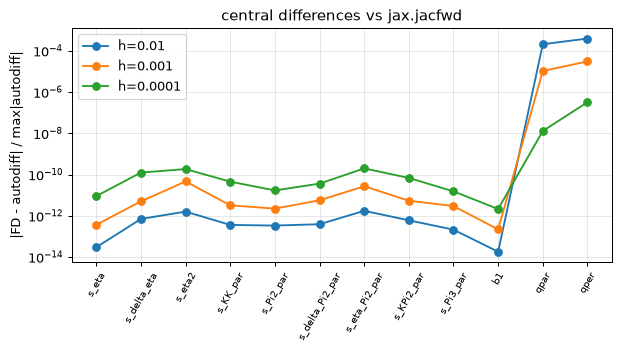

In [22]:
if parity is not None:
    jac = parity["jac"]; labels = list(SelectionBias._fields) + ["b1", "qpar", "qper"]
    fig, ax = plt.subplots(figsize=(7, 4))
    for h_ in (1e-2, 1e-3, 1e-4):
        err = np.max(np.abs(parity[f"fd_{h_:g}"] - jac), axis=(0, 1)) / np.max(np.abs(jac), axis=(0, 1))
        ax.semilogy(range(len(labels)), np.maximum(err, 1e-17), "o-", label=f"h={h_:g}")
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=60, fontsize=8)
    ax.set(ylabel="|FD - autodiff| / max|autodiff|", title="central differences vs jax.jacfwd"); ax.legend()
    fig.tight_layout(); fig.savefig(OUTPUT_DIR / "derivatives.png")
    rel_A = float(np.max(np.abs(parity["dA_ad"] - parity["dA_fd"])) / np.max(np.abs(parity["dA_ad"])))
    check("autodiff vs FD (selection, b1)", np.all(np.max(np.abs(parity["fd_0.01"] - jac), axis=(0, 1))[:10] / np.max(np.abs(jac), axis=(0, 1))[:10] < 1e-8), "exact for polynomial directions")
    check("autodiff vs FD (amplitude of P_L)", rel_A < 1e-6, f"{rel_A:.1e}")
else:
    skip("autodiff vs FD", "JAX not installed")
# NumPy route: finite-difference step convergence for an AP direction
steps = [1e-2, 3e-3, 1e-3, 3e-4]
d_ = [(calc.get_rsd_pkell(kobs, 1.02 + s_, 0.99, pars, table, table_now, damping=None, selection=selection, selection_tables=sel_tables)
       - calc.get_rsd_pkell(kobs, 1.02 - s_, 0.99, pars, table, table_now, damping=None, selection=selection, selection_tables=sel_tables)) / (2 * s_) for s_ in steps]
print("NumPy FD dP/dqpar, successive step differences:", [float(np.max(abs(d_[i+1] - d_[i])) / np.max(abs(d_[-1]))) for i in range(3)])

*Figure: agreement of central finite differences with JAX forward-mode derivatives for each supported direction and step size (polynomial directions are exact at any step up to round-off; AP converges as \(h^2\)).*

## 22. Fisher handoff (toy example)

The downstream DESI/desilike pipeline needs the data vector \((\ell,k)\) in its ordering, the
Jacobian with respect to the parameters and the covariance. **No DESI covariance or window
is used here.** The covariance below is a diagonal Gaussian *toy*
(\(V=1\,(h^{-1}{\rm Gpc})^3\), \(\bar n=2\times10^{-4}\), \(\Delta k=0.005\)), clearly not a DESI
forecast. We report the rank and conditioning of the Fisher matrix rather than inverting
it blindly.

In [23]:
kd = np.arange(0.02, 0.20, 0.005); ells = (0, 2, 4)
order = [(l, float(k_)) for l in ells for k_ in kd]                 # data-vector ordering: ell-major
def model_vec(theta):
    s_ = SelectionBias(*theta[:9]); p_ = list(pars); p_[0] = theta[9]
    return calc.get_rsd_pkell(kd, theta[10], theta[11], p_, table, table_now, damping=None,
                              selection=s_, selection_tables=sel_tables).ravel()
theta0 = np.array(list(selection) + [pars[0], 1.0, 1.0]); names_t = list(SelectionBias._fields) + ["b1", "qpar", "qper"]
J = np.stack([(model_vec(theta0 + e) - model_vec(theta0 - e)) / (2 * 1e-3) for e in 1e-3 * np.eye(theta0.size)], -1)
V, nbar, dk = 1e9, 2e-4, 0.005
Nk = V * 4 * np.pi * kd**2 * dk / (2 * np.pi)**3
P0d = model_vec(theta0).reshape(3, -1)[0]
sig = np.concatenate([(2*l + 1) * (P0d + 1/nbar) * np.sqrt(2 / Nk) for l in ells])  # crude diagonal toy errors
F = (J / sig[:, None]**2).T @ J
w, U = np.linalg.eigh(F)
print("Jacobian shape:", J.shape, "(ell*k, parameters)")
print("Fisher eigenvalues:", np.array2string(w, precision=2))
print("rank (rel. tol 1e-10):", int(np.sum(w > 1e-10 * w.max())), "of", F.shape[0], "; condition number:", f"{w.max()/max(w.min(),1e-300):.2e}")
np.savez(OUTPUT_DIR / "fisher_handoff_toy.npz", J=J, order=np.array(order), names=np.array(names_t), theta0=theta0, toy_sigma=sig,
         note="TOY diagonal covariance; not a DESI forecast")

Jacobian shape: (108, 12) (ell*k, parameters)
Fisher eigenvalues: [7.74e-07 4.24e-04 8.82e-04 3.95e-03 2.74e-01 4.26e+00 1.23e+01 5.19e+01
 9.64e+01 1.69e+03 2.75e+03 6.61e+04]
rank (rel. tol 1e-10): 11 of 12 ; condition number: 8.54e+10


## 23. Runtime and validation summary

Wall times measured on this machine (cold: matrices computed; warm: cached).

In [24]:
from folps import selection_matrices as smod
smod._MEMORY_CACHE.clear()
t0 = time.perf_counter(); get_selection_matrices(b_nu=-0.1); get_selection_matrices(b_nu=P22_TILT_LOCAL); t_mat = time.perf_counter() - t0
t0 = time.perf_counter(); nonlinear.calculate_loop_table(k=k_in, pklin=pk_in, cosmo=None, **cosmo); t_legacy = time.perf_counter() - t0
t0 = time.perf_counter(); tabs_ = build_selection_tables(nonlinear); t_sel = time.perf_counter() - t0
t0 = time.perf_counter()
for _ in range(20):
    calc.get_rsd_pkell(kobs, 1.0, 1.0, pars, table, table_now, damping=None)
t_leg = (time.perf_counter() - t0) / 20
t0 = time.perf_counter()
for _ in range(20):
    calc.get_rsd_pkell(kobs, 1.0, 1.0, pars, table, table_now, damping=None, selection=selection, selection_tables=tabs_)
t_selp = (time.perf_counter() - t0) / 20
timing = {"selection matrices, cold (2 tilts, nfftlog=128) [s]": t_mat, "legacy loop tables [s]": t_legacy,
          "selection templates, warm matrices [s]": t_sel, "legacy multipoles (60 k) [ms]": 1e3 * t_leg,
          "selected multipoles (60 k) [ms]": 1e3 * t_selp}
for k_, v in timing.items():
    print(f"{k_:52s} {v:9.3f}")
print("\nValidation summary")
for name, (status, detail) in CHECKS.items():
    print(f"  {status:8s} {name}  {detail}")
n_fail = sum(1 for s_, _ in CHECKS.values() if s_ == "FAIL")
print(f"\n{sum(1 for s_, _ in CHECKS.values() if s_ == 'PASS')} passed, {n_fail} failed, {sum(1 for s_, _ in CHECKS.values() if s_ == 'SKIPPED')} skipped")

selection matrices, cold (2 tilts, nfftlog=128) [s]     13.416
legacy loop tables [s]                                   0.059
selection templates, warm matrices [s]                   0.031
legacy multipoles (60 k) [ms]                           14.788
selected multipoles (60 k) [ms]                         51.865

Validation summary
  PASS     tree bA identity  max |diff| = 4.4e-16
  PASS     Z2 permutation + LOS reversal  0.0e+00
  PASS     Z2 oracle vs ten-kernel table  7.1e-15
  PASS     Z2 mapped field vs exact rest-frame map  3.6e-15
  PASS     Z2 at zero selection = standard RSD Z2  3.6e-15
  PASS     components add up to total  
  PASS     cubic coordinates enter linearly  curvature/response < 1e-8 for the four cubic coordinates
  PASS     IR: selected - unselected = mixed increments  
  PASS     physical derivative mode = converted polynomial  (c0,c2,c4,c6) = [-3.29  -0.208 -0.235 -0.205]
  PASS     double derivative parameterization rejected  physical_derivatives replaces the 

## 24. Export and next steps

Spectra, components, metadata and the validation summary are written to `OUTPUT_DIR`.

* **A new linear spectrum:** pass `k, pklin` (and optionally `pknow`) to
  `calculate_loop_table` with `kernels="EdS"` and call `build_selection_tables` again; the
  matrices are reused from the cache.
* **DESI Fisher / NERSC simulations:** use `get_rsd_pkell(..., selection=..., selection_tables=...)`
  inside the existing desilike pipeline, which applies the window and cuts. Build the
  tables once per cosmology, call per parameter point, and use
  `get_rsd_pkell_marg_derivatives(..., selection=...)` only for the genuinely linear
  EFT/stochastic parameters. See `docs/selection_1loop_validation.md` (integration
  interfaces).
* **`fk` / massive neutrinos:** not implemented. The selection kernels must be rederived
  with scale-dependent growth: velocity kernels, convective time derivatives of
  \(\Pi^{[a]}\), and the operator-basis equivalences, which are EdS identities. A global
  \(f\to f(k)\) substitution is not a valid shortcut; the code rejects `fk` tables in
  selection mode.

In [25]:
export = {"kobs": kobs, "P_selected": P_sel, "P_unselected": P_std, "P_selected_AP": P_ap}
export.update({f"component_{k_}": v for k_, v in comp.items() if not isinstance(v, str)})
np.savez(OUTPUT_DIR / "selection_tutorial_spectra.npz", **export)
(OUTPUT_DIR / "selection_tutorial_metadata.json").write_text(json.dumps(
    {"environment": info, "selection": selection._asdict(), "pars": pars, "cosmo": cosmo,
     "checks": {k_: list(v) for k_, v in CHECKS.items()}, "timing": timing}, indent=1, default=str))
print("written to", OUTPUT_DIR)
assert n_fail == 0, "some validation checks failed"

written to /global/u1/a/aaviles/Folps_IA/FolpsD/notebooks/selection_tutorial_outputs
